In [ ]:
STOCKHOLM COURSE SIMULATOR V1.3


MS STOCKHOLM — FORWARD SIMULATION V1.3

Partenza:       13:51:00
Velocità:       18.5 kn
Passo:          6 s
Accostata max:  3.0° / step

CORRENTI
Labrador:       0.30 kn verso 0.0° (13:45:00–00:45:00) ON
Marea:          0.40 kn verso 315.0° (21:00:00–22:30:00) ON

Shelf drift:    0.10 kn verso 90.0° (13:51:00–00:45:00) ON
Gulf fringe:    1.00 kn verso 80.0° (13:51:00–00:45:00) ON

POSIZIONI DI CONTROLLO
------------------------------------------------------------------------
20:00:00  Lat 40.480603  Lon -71.325090  rotta 89.5°  COG 88.58°  SOG 18.562 kn
21:40:00  Lat 40.500479  Lon -70.623013  rotta 88.5°  COG 86.31°  SOG 19.272 kn
23:11:00  Lat 40.522429  Lon -69.980098  rotta 98.5°  COG 96.68°  SOG 19.431 kn

ATTRAVERSAMENTO DELLA LONGITUDINE DI NANTUCKET
------------------------------------------------------------------------
Tempo:              00:28:38
Latitudine:         40.473699°N
Scarto:              4.58 NM a SUD

VERIFICA ALLE 23:11
----------------------------------------

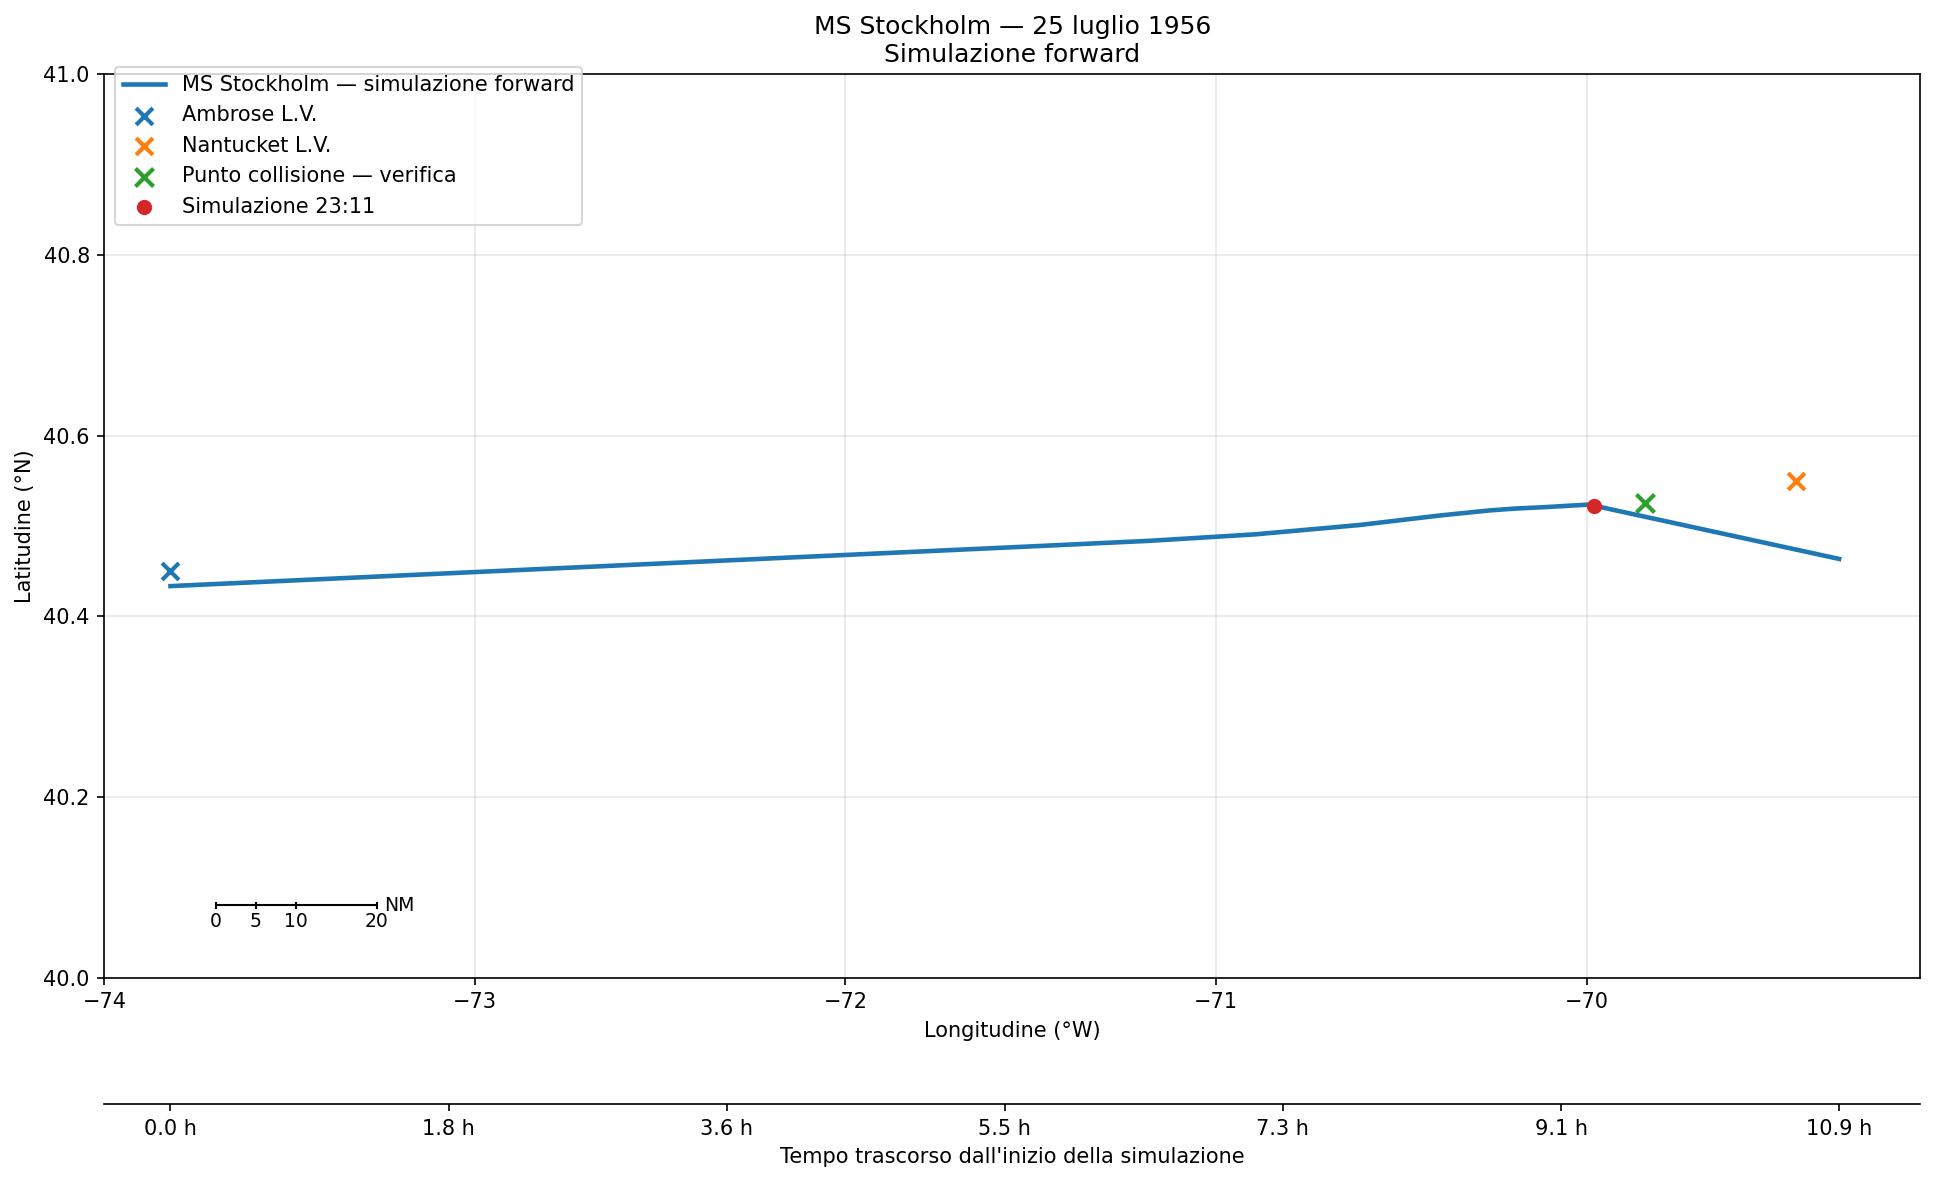


TEST SENZA ALCUNA CORRENTE (TUTTE SPENTE)

MS STOCKHOLM — FORWARD SIMULATION V1.3

Partenza:       13:51:00
Velocità:       18.5 kn
Passo:          6 s
Accostata max:  3.0° / step

CORRENTI
Labrador:       0.30 kn verso 0.0° (13:45:00–00:45:00) OFF
Marea:          0.40 kn verso 315.0° (21:00:00–22:30:00) OFF

Shelf drift:    0.10 kn verso 90.0° (13:51:00–00:45:00) OFF
Gulf fringe:    1.00 kn verso 80.0° (13:51:00–00:45:00) OFF

POSIZIONI DI CONTROLLO
------------------------------------------------------------------------
20:00:00  Lat 40.449874  Lon -71.331874  rotta 89.5°  COG 89.50°  SOG 18.500 kn
21:40:00  Lat 40.454353  Lon -70.657028  rotta 88.5°  COG 88.50°  SOG 18.500 kn
23:11:00  Lat 40.460405  Lon -70.043047  rotta 98.5°  COG 98.50°  SOG 18.500 kn

ATTRAVERSAMENTO DELLA LONGITUDINE DI NANTUCKET
------------------------------------------------------------------------
Tempo:              00:42:23
Latitudine:         40.391036°N
Scarto:              9.54 NM a SUD

VERIFICA ALLE

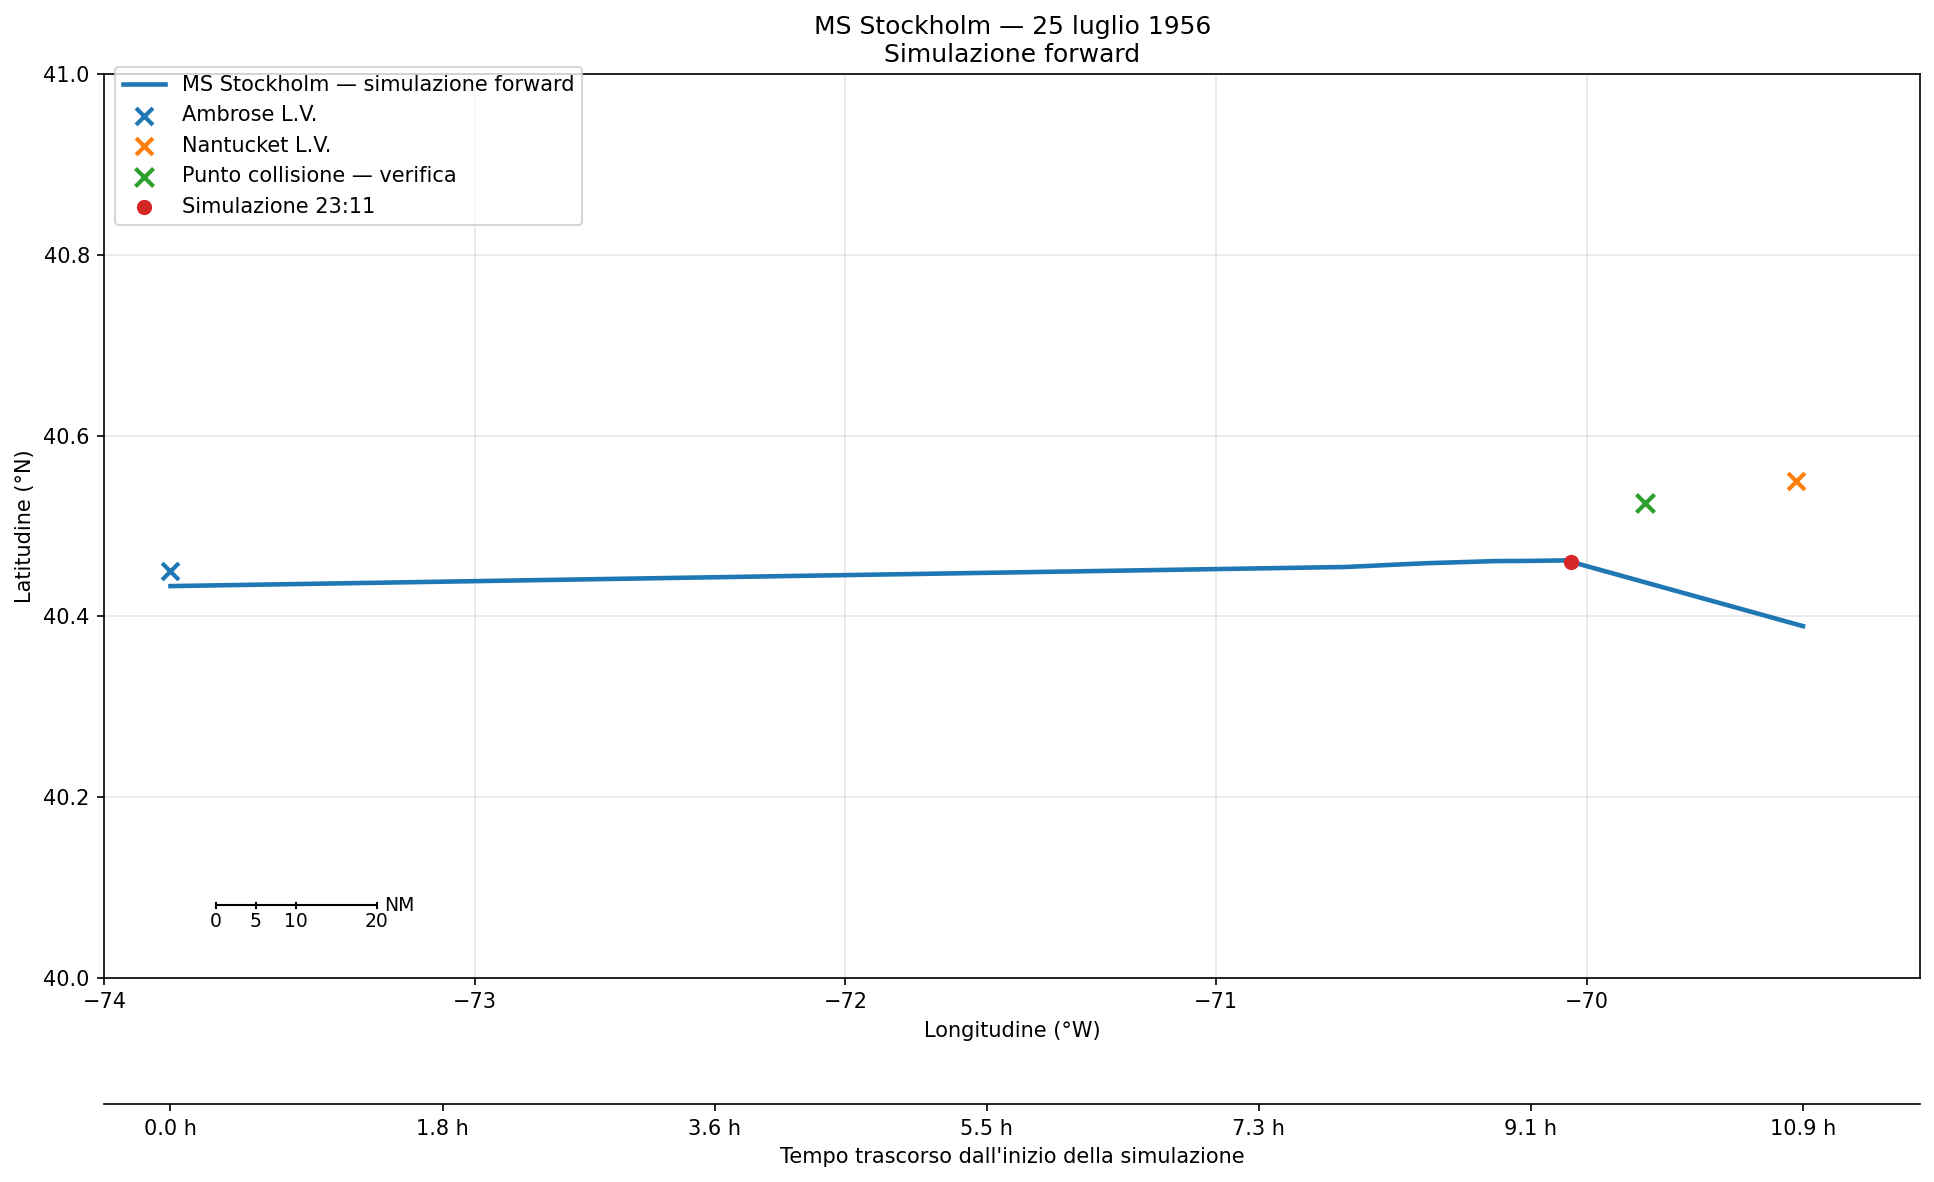

In [1]:
# -*- coding: utf-8 -*-
"""
MS STOCKHOLM — FORWARD NAVIGATION SIMULATION V1.3
25 July 1956

Metodo:
- simulazione feed-forward;
- punto di collisione usato SOLO come verifica;
- integrazione ogni 6 secondi;
- 3° di accostata = variazione di rotta eseguita in un singolo step di 6 s;
- correnti rappresentate come vettori di velocità sul fondo.

Convenzioni:
  0°  = Nord
  90° = Est
  180° = Sud
  270° = Ovest

La direzione della corrente è quella VERSO CUI la corrente scorre.
"""

from dataclasses import dataclass
from datetime import datetime, timedelta
from math import radians, degrees, sin, cos, asin, atan2, sqrt
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# PARAMETRI GENERALI
# ============================================================

DATE = "1956-07-25"

# Ora di inizio della simulazione.
# Storicamente Stockholm passò vicino ad Ambrose L.V. intorno alle 13:51.
START_TIME = "13:51:00"

# Ora di fine massima della simulazione.
# 00:45 del giorno successivo consente di superare Nantucket L.V.
END_TIME = "00:45:00"

# Passo temporale.
DT_SECONDS = 6

# Velocità Stockholm.
STOCKHOLM_SPEED_KNOTS = 18.5


# ============================================================
# MODELLO DI ACCOSTATA E ROTTA INIZIALE
# ============================================================

# Una accostata di 3° viene eseguita in un singolo intervallo di 6 s.
MAX_COURSE_CHANGE_PER_STEP_DEG = 3.0

# Condizione iniziale basata sul tracciato del course recorder
INITIAL_COURSE_DEG = 89.5   # rotta teorica 90° - rotta vera 89.5°


# ============================================================
# SEQUENZA CAMBI DI ROTTA STORICI (Da Course Recorder)
# ============================================================
# Per attivare o disattivare un cambio di rotta, basta aggiungere
# o togliere il carattere di commento (#) davanti alla tupla.
# Puoi modificare direttamente i valori in gradi e gli orari.

USE_COURSE_SCHEDULE = True

COURSE_SCHEDULE = [
    ("21:40:00", 88.5),       # rotta teorica 87° - rotta vera 88.5°
    ("22:10:00", 89.0),       # rotta teorica 2° dx - rotta vera 89°
    ("22:40:00", 90.0),       # rotta teorica 2° dx - rotta vera 90°
    ("22:50:00", 89.5),       # cambio rotta non ordinato, rotta vera 89.5°
    ("23:08:00", 92.5),       # imbardata 3° dx del timoniere Larsen
    ("23:09:00", 116.5),      # rotta teorica 2 quarte dx
    ("23:10:00", 129.5),      # prosegue accostata dx
]


# ============================================================
# POSIZIONI STORICHE
# ============================================================

# Ambrose Lightship: 40°27'N, 73°49'.3W
AMBROSE_LAT = 40.0 + 27.0 / 60.0
AMBROSE_LON = -(73.0 + 49.3 / 60.0)

# Nantucket Lightship: 40°33'N, 69°26'W
NANTUCKET_LAT = 40.0 + 33.0 / 60.0
NANTUCKET_LON = -(69.0 + 26.0 / 60.0)

# Punto di collisione: 40°31'.5N, 69°50'.6W
# SOLO VERIFICA — NON È UN INPUT DELLA SIMULAZIONE.
COLLISION_LAT = 40.0 + 31.5 / 60.0
COLLISION_LON = -(69.0 + 50.6 / 60.0)
COLLISION_TIME = "23:11:00"


# ============================================================
# POSIZIONE INIZIALE
# ============================================================

START_OFFSET_NM = -1.0
START_OFFSET_BEARING_DEG = 0.0


# ============================================================
# CORRENTE DEL LABRADOR
# ============================================================

@dataclass
class Current:
    speed_knots: float
    direction_deg: float
    start_time: str
    end_time: str
    enabled: bool = True

LABRADOR_CURRENT = Current(
    speed_knots=0.3,
    direction_deg=0.0,
    start_time="13:45:00",
    end_time="00:45:00",
    enabled=True,
)

USE_LABRADOR_CURRENT = True


# ============================================================
# CORRENTE DI MAREA — AREA RHODE ISLAND SOUND
# ============================================================

TIDAL_CURRENT = Current(
    speed_knots=0.4,
    direction_deg=315.0,
    start_time="21:00:00",
    end_time="22:30:00",
    enabled=True,
)

USE_TIDAL_CURRENT = True

TIDAL_ZONE = {
    "min_lat": 40.30,
    "max_lat": 40.90,
    "min_lon": -72.50,
    "max_lon": -70.20,
}


# ============================================================
# CORRENTE DI PIATTAFORMA / SLOPE-WATER — TEST BASATO SULLE
# EVIDENZE STORICHE DI KETCHUM & KEEN / BUMPUS
# ============================================================

USE_HISTORICAL_SHELF_DRIFT = True

HISTORICAL_SHELF_DRIFT = Current(
    speed_knots=0.1,
    direction_deg=90.0,       # Est
    start_time="13:51:00",
    end_time="00:45:00",
    enabled=True,
)

HISTORICAL_SHELF_ZONE = {
    "min_lat": 40.20,
    "max_lat": 40.80,
    "min_lon": -72.80,
    "max_lon": -69.40,
}

USE_EASTWARD_TAPER = True


def historical_shelf_weight(lat, lon):
    if not (
        HISTORICAL_SHELF_ZONE["min_lat"] <= lat
        <= HISTORICAL_SHELF_ZONE["max_lat"]
        and
        HISTORICAL_SHELF_ZONE["min_lon"] <= lon
        <= HISTORICAL_SHELF_ZONE["max_lon"]
    ):
        return 0.0

    if not USE_EASTWARD_TAPER:
        return 1.0

    west = HISTORICAL_SHELF_ZONE["min_lon"]
    east = HISTORICAL_SHELF_ZONE["max_lon"]

    if east == west:
        return 1.0

    weight = (east - lon) / (east - west)
    return max(0.0, min(1.0, weight))


# ============================================================
# POSSIBLE GULF STREAM FRINGE / MESOSCALE EFFECT
# ============================================================

USE_GULF_STREAM_FRINGE = True

GULF_STREAM_CURRENT = Current(
    speed_knots=1,
    direction_deg=80.0,       # NE
    start_time="13:51:00",
    end_time="00:45:00",
    enabled=True,
)

GULF_STREAM_ZONE = {
    "min_lat": 39.80,
    "max_lat": 40.65,
    "min_lon": -71.20,
    "max_lon": -68.90,
}

END_MARGIN_NM = 10.0
EARTH_RADIUS_NM = 3440.065


# ============================================================
# FUNZIONI TEMPORALI
# ============================================================

def parse_time(hhmmss):
    h, m, s = map(int, hhmmss.split(":"))
    date_string = DATE if h >= 12 else "1956-07-26"
    return datetime.strptime(f"{date_string} {hhmmss}", "%Y-%m-%d %H:%M:%S")


def time_window_active(t, start_time, end_time):
    start = parse_time(start_time)
    end = parse_time(end_time)

    if end < start:
        end += timedelta(days=1)

    test_time = t
    if test_time < start and end.date() > start.date():
        test_time += timedelta(days=1)

    return start <= test_time <= end


# ============================================================
# GEOMETRIA
# ============================================================

def destination_point(lat, lon, bearing_deg, distance_nm):
    phi1 = radians(lat)
    lam1 = radians(lon)
    bearing = radians(bearing_deg)
    angular_distance = distance_nm / EARTH_RADIUS_NM

    phi2 = asin(
        sin(phi1) * cos(angular_distance)
        + cos(phi1) * sin(angular_distance) * cos(bearing)
    )
    lam2 = lam1 + atan2(
        sin(bearing) * sin(angular_distance) * cos(phi1),
        cos(angular_distance) - sin(phi1) * sin(phi2),
    )
    lat2 = degrees(phi2)
    lon2 = degrees(lam2)
    lon2 = ((lon2 + 180.0) % 360.0) - 180.0
    return lat2, lon2


def distance_nm(lat1, lon1, lat2, lon2):
    phi1 = radians(lat1)
    phi2 = radians(lat2)
    dphi = radians(lat2 - lat1)
    dlam = radians(lon2 - lon1)
    a = sin(dphi / 2.0) ** 2 + cos(phi1) * cos(phi2) * sin(dlam / 2.0) ** 2
    a = min(1.0, max(0.0, a))
    return 2.0 * EARTH_RADIUS_NM * asin(sqrt(a))


# ============================================================
# VETTORI
# ============================================================

def vector_from_speed_course(speed_knots, direction_deg):
    angle = radians(direction_deg)
    north = speed_knots * cos(angle)
    east = speed_knots * sin(angle)
    return north, east


def course_from_vector(north, east):
    return (degrees(atan2(east, north)) + 360.0) % 360.0


# ============================================================
# ACCOSTATA
# ============================================================

def advance_course(current_course, target_course):
    delta = (target_course - current_course + 180.0) % 360.0 - 180.0
    if abs(delta) <= MAX_COURSE_CHANGE_PER_STEP_DEG:
        return target_course % 360.0
    step = np.sign(delta) * MAX_COURSE_CHANGE_PER_STEP_DEG
    return (current_course + step) % 360.0


# ============================================================
# CORRENTI
# ============================================================

def current_is_active(current, t):
    return (
        current.enabled
        and current.speed_knots != 0.0
        and time_window_active(t, current.start_time, current.end_time)
    )


def tidal_zone_active(lat, lon):
    return TIDAL_ZONE["min_lat"] <= lat <= TIDAL_ZONE["max_lat"] and TIDAL_ZONE["min_lon"] <= lon <= TIDAL_ZONE["max_lon"]


def gulf_stream_zone_active(lat, lon):
    return GULF_STREAM_ZONE["min_lat"] <= lat <= GULF_STREAM_ZONE["max_lat"] and GULF_STREAM_ZONE["min_lon"] <= lon <= GULF_STREAM_ZONE["max_lon"]


def historical_shelf_zone_active(lat, lon):
    return HISTORICAL_SHELF_ZONE["min_lat"] <= lat <= HISTORICAL_SHELF_ZONE["max_lat"] and HISTORICAL_SHELF_ZONE["min_lon"] <= lon <= HISTORICAL_SHELF_ZONE["max_lon"]


# ============================================================
# SIMULAZIONE
# ============================================================

def simulate():
    start_datetime = parse_time(START_TIME)
    end_datetime = parse_time(END_TIME)

    if end_datetime <= start_datetime:
        end_datetime += timedelta(days=1)

    lat, lon = destination_point(AMBROSE_LAT, AMBROSE_LON, START_OFFSET_BEARING_DEG, START_OFFSET_NM)
    commanded_course = INITIAL_COURSE_DEG

    collision_datetime = parse_time(COLLISION_TIME)

    # Preparazione della lista dei cambi rotta ordinati cronologicamente
    schedule_events = []
    if USE_COURSE_SCHEDULE:
        for t_str, c_val in COURSE_SCHEDULE:
            schedule_events.append({"time": parse_time(t_str), "course": c_val})
        schedule_events.sort(key=lambda x: x["time"])

    total_seconds = (end_datetime - start_datetime).total_seconds()
    number_of_steps = int(total_seconds / DT_SECONDS) + 1
    trajectory = []

    for step in range(number_of_steps):
        t = start_datetime + timedelta(seconds=step * DT_SECONDS)

        # Controllo e applicazione dei cambi di rotta programmati
        if USE_COURSE_SCHEDULE:
            for event in schedule_events:
                if t >= event["time"]:
                    commanded_course = advance_course(commanded_course, event["course"])

        north, east = vector_from_speed_course(STOCKHOLM_SPEED_KNOTS, commanded_course)

        if USE_LABRADOR_CURRENT and current_is_active(LABRADOR_CURRENT, t):
            cn, ce = vector_from_speed_course(LABRADOR_CURRENT.speed_knots, LABRADOR_CURRENT.direction_deg)
            north += cn
            east += ce

        if USE_TIDAL_CURRENT and tidal_zone_active(lat, lon) and current_is_active(TIDAL_CURRENT, t):
            cn, ce = vector_from_speed_course(TIDAL_CURRENT.speed_knots, TIDAL_CURRENT.direction_deg)
            north += cn
            east += ce

        if USE_HISTORICAL_SHELF_DRIFT and historical_shelf_zone_active(lat, lon) and current_is_active(HISTORICAL_SHELF_DRIFT, t):
            weight = historical_shelf_weight(lat, lon)
            cn, ce = vector_from_speed_course(HISTORICAL_SHELF_DRIFT.speed_knots * weight, HISTORICAL_SHELF_DRIFT.direction_deg)
            north += cn
            east += ce

        if USE_GULF_STREAM_FRINGE and gulf_stream_zone_active(lat, lon) and current_is_active(GULF_STREAM_CURRENT, t):
            cn, ce = vector_from_speed_course(GULF_STREAM_CURRENT.speed_knots, GULF_STREAM_CURRENT.direction_deg)
            north += cn
            east += ce

        speed_over_ground = sqrt(north ** 2 + east ** 2)
        ground_course = course_from_vector(north, east)

        trajectory.append({
            "time": t,
            "lat": lat,
            "lon": lon,
            "commanded_course": commanded_course,
            "ground_course": ground_course,
            "sog": speed_over_ground,
        })

        distance_step_nm = speed_over_ground * DT_SECONDS / 3600.0
        lat, lon = destination_point(lat, lon, ground_course, distance_step_nm)

        if t > collision_datetime and lon >= NANTUCKET_LON and distance_nm(lat, lon, NANTUCKET_LAT, NANTUCKET_LON) >= END_MARGIN_NM:
            break

    return trajectory


# ============================================================
# INTERPOLAZIONE E REPORT
# ============================================================

def interpolate_at_longitude(trajectory, target_lon):
    for a, b in zip(trajectory[:-1], trajectory[1:]):
        if a["lon"] <= target_lon <= b["lon"]:
            denominator = b["lon"] - a["lon"]
            if denominator == 0:
                continue
            fraction = (target_lon - a["lon"]) / denominator
            lat = a["lat"] + fraction * (b["lat"] - a["lat"])
            seconds_a = (a["time"] - trajectory[0]["time"]).total_seconds()
            seconds_b = (b["time"] - trajectory[0]["time"]).total_seconds()
            seconds = seconds_a + fraction * (seconds_b - seconds_a)
            time = trajectory[0]["time"] + timedelta(seconds=seconds)
            return lat, time
    return None, None


def nearest_record(trajectory, target_datetime):
    return min(trajectory, key=lambda r: abs((r["time"] - target_datetime).total_seconds()))


def print_report(trajectory):
    print()
    print("=" * 72)
    print("MS STOCKHOLM — FORWARD SIMULATION V1.3")
    print("=" * 72)
    print()
    print(f"Partenza:       {START_TIME}")
    print(f"Velocità:       {STOCKHOLM_SPEED_KNOTS:.1f} kn")
    print(f"Passo:          {DT_SECONDS} s")
    print(f"Accostata max:  {MAX_COURSE_CHANGE_PER_STEP_DEG:.1f}° / step")
    print()

    print("CORRENTI")
    print(f"Labrador:       {LABRADOR_CURRENT.speed_knots:.2f} kn verso {LABRADOR_CURRENT.direction_deg:.1f}° ({LABRADOR_CURRENT.start_time}–{LABRADOR_CURRENT.end_time}) {'ON' if USE_LABRADOR_CURRENT else 'OFF'}")
    print(f"Marea:          {TIDAL_CURRENT.speed_knots:.2f} kn verso {TIDAL_CURRENT.direction_deg:.1f}° ({TIDAL_CURRENT.start_time}–{TIDAL_CURRENT.end_time}) {'ON' if USE_TIDAL_CURRENT else 'OFF'}")
    print()
    print(f"Shelf drift:    {HISTORICAL_SHELF_DRIFT.speed_knots:.2f} kn verso {HISTORICAL_SHELF_DRIFT.direction_deg:.1f}° ({HISTORICAL_SHELF_DRIFT.start_time}–{HISTORICAL_SHELF_DRIFT.end_time}) {'ON' if USE_HISTORICAL_SHELF_DRIFT else 'OFF'}")
    print(f"Gulf fringe:    {GULF_STREAM_CURRENT.speed_knots:.2f} kn verso {GULF_STREAM_CURRENT.direction_deg:.1f}° ({GULF_STREAM_CURRENT.start_time}–{GULF_STREAM_CURRENT.end_time}) {'ON' if USE_GULF_STREAM_FRINGE else 'OFF'}")
    print()

    print("POSIZIONI DI CONTROLLO")
    print("-" * 72)

    for hhmmss in ["20:00:00", "21:40:00", COLLISION_TIME]:
        target = parse_time(hhmmss)
        record = nearest_record(trajectory, target)
        print(f"{hhmmss}  Lat {record['lat']:.6f}  Lon {record['lon']:.6f}  rotta {record['commanded_course']:.1f}°  COG {record['ground_course']:.2f}°  SOG {record['sog']:.3f} kn")

    print()

    lat_nantucket, time_nantucket = interpolate_at_longitude(trajectory, NANTUCKET_LON)
    if lat_nantucket is not None:
        offset_nm = (NANTUCKET_LAT - lat_nantucket) * 60.0
        print("ATTRAVERSAMENTO DELLA LONGITUDINE DI NANTUCKET")
        print("-" * 72)
        print(f"Tempo:              {time_nantucket:%H:%M:%S}")
        print(f"Latitudine:         {lat_nantucket:.6f}°N")
        if offset_nm >= 0:
            print(f"Scarto:              {offset_nm:.2f} NM a SUD")
        else:
            print(f"Scarto:              {abs(offset_nm):.2f} NM a NORD")
        print()

    collision_record = nearest_record(trajectory, parse_time(COLLISION_TIME))
    verification_distance = distance_nm(collision_record["lat"], collision_record["lon"], COLLISION_LAT, COLLISION_LON)

    print("VERIFICA ALLE 23:11")
    print("-" * 72)
    print(f"Simulazione: {collision_record['lat']:.6f}°N, {abs(collision_record['lon']):.6f}°W")
    print(f"Punto storico: {COLLISION_LAT:.6f}°N, {abs(COLLISION_LON):.6f}°W")
    print(f"Distanza simulazione → punto collisione: {verification_distance:.3f} NM")
    print()
    print("=" * 72)
    print()


# ============================================================
# GRAFICO
# ============================================================

def plot_trajectory(trajectory):
    lats = np.array([r["lat"] for r in trajectory])
    lons = np.array([r["lon"] for r in trajectory])
    times = [r["time"] for r in trajectory]

    fig, ax = plt.subplots(figsize=(13, 8), dpi=150)

    # Traiettoria principale
    ax.plot(
        lons,
        lats,
        linewidth=2.2,
        label="MS Stockholm — simulazione forward",
    )

    # Punti storici (ora tutti con marcatore a crocetta "x" per la massima precisione di carteggio)
    ax.scatter(
        AMBROSE_LON,
        AMBROSE_LAT,
        s=65,
        marker="x",
        linewidths=2,
        zorder=5,
        label="Ambrose L.V.",
    )

    ax.scatter(
        NANTUCKET_LON,
        NANTUCKET_LAT,
        s=65,
        marker="x",
        linewidths=2,
        zorder=5,
        label="Nantucket L.V.",
    )

    ax.scatter(
        COLLISION_LON,
        COLLISION_LAT,
        s=75,
        marker="x",
        linewidths=2,
        zorder=6,
        label="Punto collisione — verifica",
    )

    collision_record = nearest_record(
        trajectory,
        parse_time(COLLISION_TIME),
    )

    ax.scatter(
        collision_record["lon"],
        collision_record["lat"],
        s=40,
        marker="o",
        zorder=6,
        label="Simulazione 23:11",
    )

    # Formato carta
    ax.set_xlim(-74.0, -69.1)
    ax.set_ylim(40.0, 41.0)
    ax.set_xlabel("Longitudine (°W)")
    ax.set_ylabel("Latitudine (°N)")
    ax.set_title("MS Stockholm — 25 luglio 1956\nSimulazione forward")
    ax.grid(True, alpha=0.30)
    ax.legend(
        loc="upper left",
        bbox_to_anchor=(0.0, 1.02),
        ncol=1,
        frameon=True,
    )

    # Scala nautica multi-segmento (stile carta d'epoca)
    scale_lat = 40.08
    scale_lon_start = -73.70
    ticks_nm = [0, 5, 10, 20]

    cos_lat = cos(radians(scale_lat))
    max_nm = max(ticks_nm)
    scale_lon_end = scale_lon_start + (max_nm / (60.0 * cos_lat))

    ax.plot(
        [scale_lon_start, scale_lon_end],
        [scale_lat, scale_lat],
        color="black",
        linewidth=1.0,
        solid_capstyle="butt",
        zorder=7
    )

    for nm in ticks_nm:
        tick_lon = scale_lon_start + (nm / (60.0 * cos_lat))
        ax.plot(
            [tick_lon, tick_lon],
            [scale_lat - 0.003, scale_lat + 0.003],
            color="black",
            linewidth=1.0,
            zorder=7
        )
        ax.text(
            tick_lon,
            scale_lat - 0.007,
            f"{int(nm)}" if nm > 0 else "0",
            ha="center",
            va="top",
            fontsize=9,
        )

    ax.text(
        scale_lon_end + 0.02,
        scale_lat,
        "NM",
        ha="left",
        va="center",
        fontsize=9,
    )

    # Asse temporale secondario
    ax_time = ax.secondary_xaxis(-0.14)
    lon_values = np.array(lons)
    elapsed_hours = np.array([
        (t - times[0]).total_seconds() / 3600.0
        for t in times
    ])

    unique_lon, unique_indices = np.unique(lon_values, return_index=True)
    unique_time = elapsed_hours[unique_indices]

    if len(unique_lon) >= 2:
        tick_values = np.linspace(unique_time[0], unique_time[-1], 7)
        ax_time.set_xticks(np.linspace(unique_lon[0], unique_lon[-1], 7))
        ax_time.set_xticklabels([f"{value:.1f} h" for value in tick_values])
        ax_time.set_xlabel("Tempo trascorso dall'inizio della simulazione")

    plt.tight_layout()
    plt.show()


# ============================================================
# TEST RAPIDI
# ============================================================

def run_no_current_test():
    global USE_LABRADOR_CURRENT, USE_TIDAL_CURRENT, USE_HISTORICAL_SHELF_DRIFT, USE_GULF_STREAM_FRINGE

    old_labrador = USE_LABRADOR_CURRENT
    old_tidal = USE_TIDAL_CURRENT
    old_shelf = USE_HISTORICAL_SHELF_DRIFT
    old_gulf = USE_GULF_STREAM_FRINGE

    USE_LABRADOR_CURRENT = False
    USE_TIDAL_CURRENT = False
    USE_HISTORICAL_SHELF_DRIFT = False
    USE_GULF_STREAM_FRINGE = False

    trajectory = simulate()

    print()
    print("=" * 72)
    print("TEST SENZA ALCUNA CORRENTE (TUTTE SPENTE)")
    print("=" * 72)

    print_report(trajectory)
    plot_trajectory(trajectory)

    USE_LABRADOR_CURRENT = old_labrador
    USE_TIDAL_CURRENT = old_tidal
    USE_HISTORICAL_SHELF_DRIFT = old_shelf
    USE_GULF_STREAM_FRINGE = old_gulf

    return trajectory


# ============================================================
# NOTE SULLE FONTI
# ============================================================
#
# Ketchum, B.H. & Keen, D.J. (1955), "The accumulation of river
# water over the continental shelf between Cape Cod and Chesapeake
# Bay":
#   - Gulf Stream offshore, separated from shelf water by slope water;
#   - non-tidal drifts south of New York ~1.8–2.8 NM/day;
#   - Ambrose Lightship: non-tidal current nearly east;
#   - frequent easterly components over the mid-shelf south of
#     Martha's Vineyard.
#
# Bumpus, D.F. (1961), "Drift Bottle Records for the Gulf of Maine,
# Georges Bank and Bay of Fundy, 1956-58", SSRF 378:
#   - surface circulation fields reconstructed from drift-bottle
#     releases/recoveries;
#   - monthly maps exist for 1958;
#   - no local numerical velocity scale is supplied that would
#     justify assigning a specific 1956 velocity to Stockholm.
#
# Therefore the collision point remains verification-only.
#
# ============================================================


# ============================================================
# MAIN
# ============================================================

if __name__ == "__main__":
    trajectory = simulate()
    print_report(trajectory)
    plot_trajectory(trajectory)

    # Test rapido facoltativo (scommentare per eseguirlo)
no_current_trajectory = run_no_current_test()